# 04 – Klassifikationsmodell: Ist der Zug verspätet (≥ 3 min)?
**Vorgehen**
1. Zeitlicher Train/Test-Split (die letzten ~30 % der Tage als Test → realistisch, kein „Blick in die Zukunft“)
2. Baseline, logistische Regression und Random Forest vergleichen
3. Gütemasse: Accuracy, Precision, Recall, F1, ROC-AUC (wegen Klassenungleichgewicht nicht nur Accuracy!)
4. **Über die reine Vorhersage hinaus:** separate Modelle für *Deutschschweiz vs. Romandie* und *Stosszeit vs. Randzeit* → unterscheiden sich Güte und wichtigste Einflussfaktoren?
5. Interpretation mit einem Logit-Modell (Odds Ratios, p-Werte)

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Datenbank:", config.DB_PATH)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from src.features import load_analysis, temporal_split, NUM_FEATURES, CAT_FEATURES, BIN_FEATURES

MAX_TRAIN = 300_000   # Stichprobe für das Training (Rechenzeit); bei Bedarf erhöhen
df = load_analysis(conn)
train, test, test_tage = temporal_split(df)
print(f"Train: {len(train):,} Zeilen | Test: {len(test):,} Zeilen | Testtage: {test_tage[0]} bis {test_tage[-1]}")
print(f"Anteil verspätet – Train: {train['verspaetet'].mean():.1%}, Test: {test['verspaetet'].mean():.1%}")

Datenbank: /Users/ayushanahilan/Documents/5. Semester/DataAnalytics/DataAnalytics_Gruppe37/data/zugverspaetung.sqlite


Train: 278,024 Zeilen | Test: 122,111 Zeilen | Testtage: 2026-10-24 bis 2026-10-27
Anteil verspätet – Train: 6.6%, Test: 5.5%


In [2]:
def make_preprocessor(cat, num_bin):
    return ColumnTransformer([
        ("kat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", StandardScaler(), num_bin),
    ])

def evaluate(name, model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = model.predict(X)
    return {"Modell": name,
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba) if len(np.unique(y)) > 1 else np.nan}

def sample(d, n):
    return d.sample(n, random_state=config.RANDOM_STATE) if len(d) > n else d

FEATURES = CAT_FEATURES + NUM_FEATURES + BIN_FEATURES
tr = sample(train, MAX_TRAIN)
X_tr, y_tr = tr[FEATURES], tr["verspaetet"]
X_te, y_te = test[FEATURES], test["verspaetet"]

## 1. Modelle trainieren und vergleichen
`class_weight="balanced"`: verspätete Züge sind die Minderheit – ohne Gewichtung würde das Modell fast immer „pünktlich“ vorhersagen.

In [3]:
modelle = {
    "Baseline (immer pünktlich)": Pipeline([("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES + BIN_FEATURES)),
                                            ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistische Regression": Pipeline([("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES + BIN_FEATURES)),
                                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES + BIN_FEATURES)),
                               ("clf", RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20,
                                                              class_weight="balanced_subsample", n_jobs=-1,
                                                              random_state=config.RANDOM_STATE))]),
}
ergebnisse = []
for name, m in modelle.items():
    m.fit(X_tr, y_tr)
    ergebnisse.append(evaluate(name, m, X_te, y_te))
ergebnisse = pd.DataFrame(ergebnisse).set_index("Modell")
display(ergebnisse.style.format("{:.3f}"))
ergebnisse.round(3).to_csv(config.OUTPUT_DIR / "04_modellvergleich.csv")

,Accuracy,Precision,Recall,F1,ROC-AUC
Modell,,,,,
Baseline (immer pünktlich),0.945,0.000,0.000,0.000,0.500
Logistische Regression,0.698,0.090,0.491,0.153,0.643
Random Forest,0.792,0.114,0.407,0.178,0.680


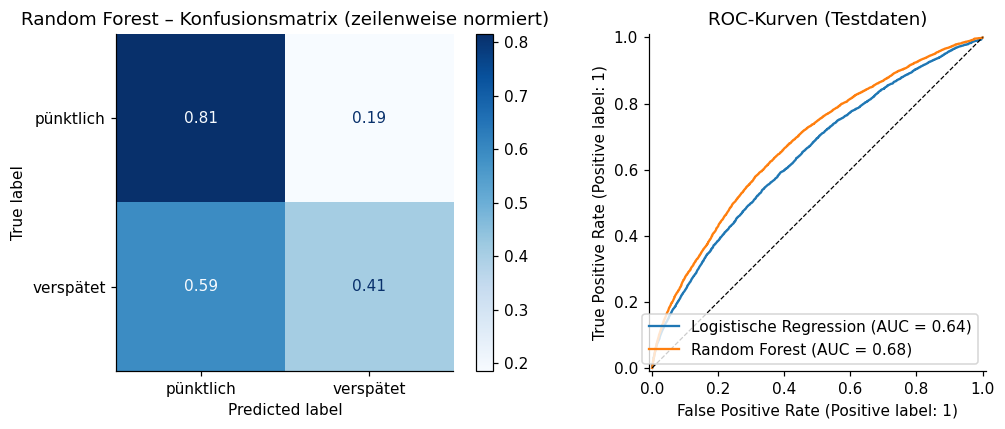

In [4]:
rf = modelle["Random Forest"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, rf.predict(X_te), normalize="true"),
                       display_labels=["pünktlich", "verspätet"]).plot(ax=axes[0], cmap="Blues", values_format=".2f")
axes[0].set_title("Random Forest – Konfusionsmatrix (zeilenweise normiert)")
for name in ["Logistische Regression", "Random Forest"]:
    RocCurveDisplay.from_estimator(modelle[name], X_te, y_te, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set_title("ROC-Kurven (Testdaten)")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "04_konfusion_roc.png", dpi=200); plt.show()

## 2. Gruppenvergleich: Unterscheiden sich die Einflussfaktoren?
Für jede Gruppe wird ein eigenes Random-Forest-Modell trainiert (ohne die Gruppenvariable selbst). Die **Permutation Importance** zeigt, wie stark die Modellgüte (ROC-AUC) sinkt, wenn ein Merkmal zufällig vertauscht wird.

In [5]:
gruppen = {
    "Deutschschweiz": ("region", "Deutschschweiz"),
    "Romandie":       ("region", "Romandie"),
    "Stosszeit":      ("zeitfenster", "Stosszeit"),
    "Randzeit":       ("zeitfenster", "Randzeit"),
}
gruppen_metriken, importances = [], {}
for gname, (spalte, wert) in gruppen.items():
    tr_g, te_g = train[train[spalte] == wert], test[test[spalte] == wert]
    if len(tr_g) < 1000 or te_g["verspaetet"].nunique() < 2:
        print(f"{gname}: zu wenige Daten – übersprungen"); continue
    weglassen = {"region": ["region"], "zeitfenster": ["stosszeit"]}[spalte]
    cat = [c for c in CAT_FEATURES if c not in weglassen]
    num = [c for c in NUM_FEATURES + BIN_FEATURES if c not in weglassen]
    tr_g = sample(tr_g, MAX_TRAIN)
    m = Pipeline([("prep", make_preprocessor(cat, num)),
                  ("clf", RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20,
                                                 class_weight="balanced_subsample", n_jobs=-1,
                                                 random_state=config.RANDOM_STATE))])
    m.fit(tr_g[cat + num], tr_g["verspaetet"])
    gruppen_metriken.append({"Gruppe": gname, "n_train": len(tr_g), "n_test": len(te_g),
                             "Anteil verspätet (Test)": te_g["verspaetet"].mean(),
                             **{k: v for k, v in evaluate(gname, m, te_g[cat + num], te_g["verspaetet"]).items() if k != "Modell"}})
    te_s = sample(te_g, 20_000)
    pi = permutation_importance(m, te_s[cat + num], te_s["verspaetet"], scoring="roc_auc",
                                n_repeats=5, random_state=config.RANDOM_STATE, n_jobs=-1)
    importances[gname] = pd.Series(pi.importances_mean, index=cat + num)

gruppen_metriken = pd.DataFrame(gruppen_metriken).set_index("Gruppe")
display(gruppen_metriken.style.format({"n_train": "{:,}", "n_test": "{:,}", "Anteil verspätet (Test)": "{:.1%}",
                                       "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
                                       "F1": "{:.3f}", "ROC-AUC": "{:.3f}"}))
gruppen_metriken.round(3).to_csv(config.OUTPUT_DIR / "04_gruppenvergleich.csv")

,n_train,n_test,Anteil verspätet (Test),Accuracy,Precision,Recall,F1,ROC-AUC
Gruppe,,,,,,,,
Deutschschweiz,"223,517","97,944",5.1%,0.826,0.115,0.360,0.174,0.679
Romandie,"43,995","19,541",7.9%,0.742,0.133,0.410,0.200,0.649
Stosszeit,"73,605","21,178",7.1%,0.889,0.109,0.080,0.092,0.583
Randzeit,"204,419","100,933",5.2%,0.773,0.114,0.492,0.185,0.698


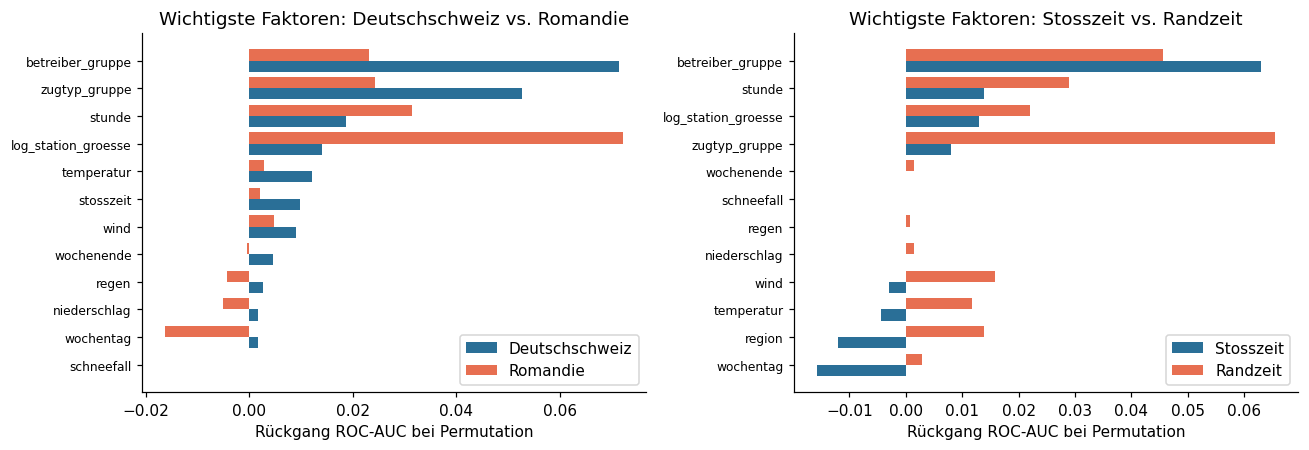

,Deutschschweiz,Romandie,Stosszeit,Randzeit
betreiber_gruppe,0.0714,0.0230,0.0630,0.0455
log_station_groesse,0.0139,0.0723,0.0129,0.0220
niederschlag,0.0017,-0.0051,0.0000,0.0015
regen,0.0025,-0.0043,0.0000,0.0007
region,NaN,NaN,-0.0120,0.0138
schneefall,0.0000,0.0000,0.0000,0.0000
stosszeit,0.0098,0.0021,NaN,NaN
stunde,0.0188,0.0315,0.0138,0.0290
temperatur,0.0121,0.0029,-0.0044,0.0117
wind,0.0090,0.0047,-0.0029,0.0158


In [6]:
imp = pd.DataFrame(importances)
paare = [("Deutschschweiz", "Romandie"), ("Stosszeit", "Randzeit")]
paare = [p for p in paare if all(x in imp.columns for x in p)]
fig, axes = plt.subplots(1, len(paare), figsize=(6 * len(paare), 4.2), squeeze=False)
for ax, (a, b) in zip(axes[0], paare):
    sub = imp[[a, b]].dropna().sort_values(a)
    y = np.arange(len(sub))
    ax.barh(y - 0.2, sub[a], height=0.4, label=a, color="#2a6f97")
    ax.barh(y + 0.2, sub[b], height=0.4, label=b, color="#e76f51")
    ax.set_yticks(y); ax.set_yticklabels(sub.index, fontsize=8)
    ax.set_xlabel("Rückgang ROC-AUC bei Permutation"); ax.set_title(f"Wichtigste Faktoren: {a} vs. {b}"); ax.legend()
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "04_feature_importance_gruppen.png", dpi=200); plt.show()
display(imp.round(4))

## 3. Interpretation mit logistischer Regression (statsmodels)
Odds Ratio > 1 → höhere Chance auf Verspätung. Der Interaktionsterm `Region × Stosszeit` testet direkt, ob der Effekt der Stosszeit in der Romandie anders ist als in der Deutschschweiz.

In [7]:
import statsmodels.formula.api as smf

d = sample(df[df["region"].isin(["Deutschschweiz", "Romandie"])], 200_000).copy()
formel = ("verspaetet ~ C(region, Treatment('Deutschschweiz')) * stosszeit + wochenende"
          " + niederschlag + temperatur + wind + C(zugtyp_gruppe, Treatment('S-Bahn')) + log_station_groesse")
logit = smf.logit(formel, data=d).fit(disp=False)
or_tab = pd.DataFrame({"Odds Ratio": np.exp(logit.params), "KI 2.5%": np.exp(logit.conf_int()[0]),
                       "KI 97.5%": np.exp(logit.conf_int()[1]), "p-Wert": logit.pvalues})
display(or_tab.style.format({"Odds Ratio": "{:.3f}", "KI 2.5%": "{:.3f}", "KI 97.5%": "{:.3f}", "p-Wert": "{:.4f}"}))
print(f"Pseudo-R² (McFadden): {logit.prsquared:.3f}")
or_tab.round(4).to_csv(config.OUTPUT_DIR / "04_logit_odds_ratios.csv")

,Odds Ratio,KI 2.5%,KI 97.5%,p-Wert
Intercept,0.012,0.009,0.015,0.0000
"C(region, Treatment('Deutschschweiz'))[T.Romandie]",1.727,1.617,1.844,0.0000
"C(zugtyp_gruppe, Treatment('S-Bahn'))[T.Andere]",2.729,2.273,3.277,0.0000
"C(zugtyp_gruppe, Treatment('S-Bahn'))[T.InterCity]",2.026,1.904,2.157,0.0000
"C(zugtyp_gruppe, Treatment('S-Bahn'))[T.InterRegio]",1.332,1.261,1.408,0.0000
"C(zugtyp_gruppe, Treatment('S-Bahn'))[T.International]",6.777,6.143,7.475,0.0000
"C(zugtyp_gruppe, Treatment('S-Bahn'))[T.Regio]",1.168,1.075,1.268,0.0002
"C(zugtyp_gruppe, Treatment('S-Bahn'))[T.RegioExpress]",1.115,1.032,1.204,0.0061
stosszeit,1.672,1.594,1.753,0.0000
"C(region, Treatment('Deutschschweiz'))[T.Romandie]:stosszeit",0.596,0.539,0.658,0.0000


Pseudo-R² (McFadden): 0.035


## 4. Interpretation
*(Stand: echte Daten, Training 14.–23.10., Test 24.–27.10.)*
- **Modellgüte:** Die Baseline erreicht 94,5 % Accuracy, erkennt aber keinen einzigen verspäteten Zug → Accuracy ist hier irreführend. Der **Random Forest** ist das beste Modell (ROC-AUC 0,68, Recall 0,41, Precision 0,11, F1 0,18) vor der logistischen Regression (ROC-AUC 0,64). Das Modell erkennt also etwa 4 von 10 Verspätungen, schlägt aber oft Fehlalarm. Mit Fahrplan-, Zug- und Wettermerkmalen lassen sich Verspätungen nur **mässig** vorhersagen; viel hängt von nicht erfassten Ereignissen ab (Störungen, Folgeverspätungen).
- **Wichtigste Faktoren insgesamt:** Betreiber und Zugtyp, danach Uhrzeit und Bahnhofsgrösse. Wetter spielt eine kleine Rolle.
- **Deutschschweiz vs. Romandie:** In der Deutschschweiz dominieren Betreiber (SBB vs. Regionalbahnen) und Zugtyp. In der Romandie ist die **Bahnhofsgrösse** der wichtigste Faktor (grosse Knoten wie Lausanne mit 12,2 % sind deutlich unpünktlicher), gefolgt von der Uhrzeit.
- **Stosszeit vs. Randzeit:** In der Randzeit ist der Zugtyp entscheidend, in der Stosszeit der Betreiber. Das Stosszeit-Modell ist schwach (ROC-AUC 0,58); die Testtage enthalten ein Wochenende, daher gibt es nur 2 Werktage mit Stosszeit im Test.
- **Logit-Modell (Odds Ratios, alle p < 0,01):** Stosszeit erhöht die Chance auf Verspätung in der Deutschschweiz um **Faktor 1,67**. Der Interaktionsterm Romandie × Stosszeit (OR 0,60) zeigt: **in der Romandie hat die Stosszeit praktisch keinen zusätzlichen Effekt** (1,67 × 0,60 ≈ 1,0), dafür ist das Grundniveau höher (OR 1,73). Weitere Effekte: Niederschlag OR 1,21 pro mm/h, internationale Züge OR 6,8 und InterCity OR 2,0 gegenüber der S-Bahn, Wochenende OR 0,77. Pseudo-R² = 0,035 → die Merkmale erklären nur einen kleinen Teil der Variation.
- **Limitationen:** nur ~2 Wochen im Herbst (kaum Schnee), Region auf Kantonsebene, Wetter am Ankunftsbahnhof (nicht entlang der Strecke), Folgeverspätungen nicht modelliert, nur 17 Bahnhöfe in der Romandie.
